
========== VERTEX CHAIN CODE (VCC) ==========

Código VCC:
1222222122231312313122312312231322222213213222132221321321321322132132132131313221321321321313132132123213213213213212321321313213132123131312313131321313132123131231312321313131313131231312312312312313213213213221232131231231321223131321232131231313131312321313213131313123213132131313213131313132131232131232212322221232213132123221232221232213212313213131313131321321321313131313131313221313213132213132213213221322132132222132222222132222222213222222222222222222222231222132222222231222222222222312222223122222222312222222312222222231222222222222223122222222222222222312222213222222222222222132222222221322132222132221322213221322132221232213132221313222133122222222312223122222222222312222222222221322132213221231322213131321321232213131232131313131223212232122313123122231312231231222231222312222312222312222222222312222222222222222213231222133122213222312221323122213222222222221322222222222222222222222222222312222223131222222222222

C:\Users\gaelg\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


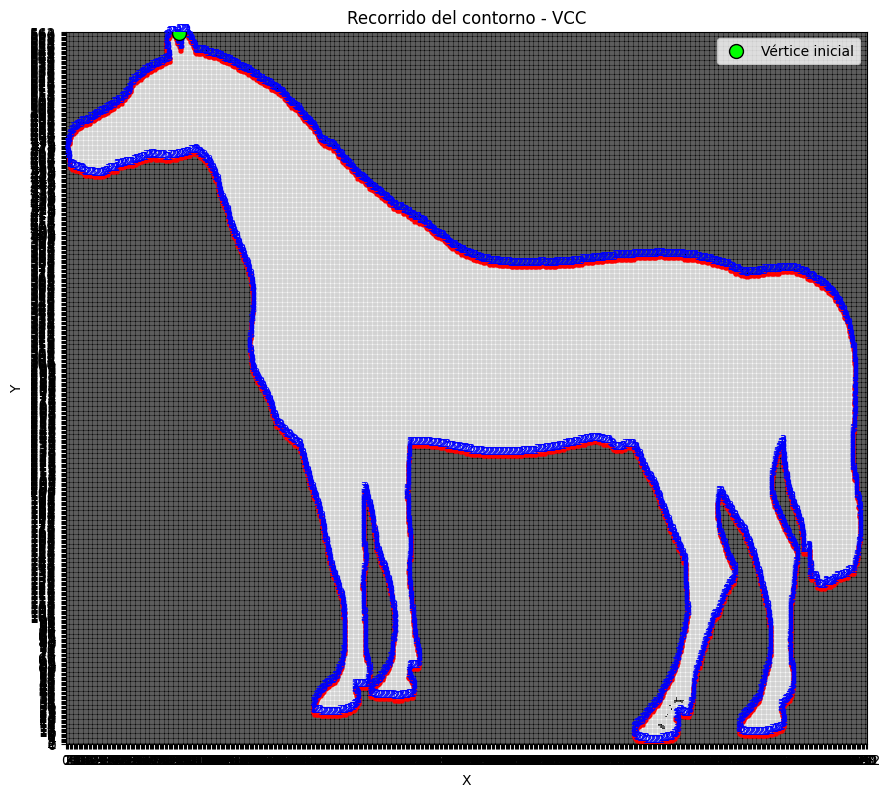

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt


# 1. Cargar imagen GIF
ruta = input("Introduce la ruta del GIF: ")

imagen = Image.open(ruta)
imagen.seek(0)
imagen = imagen.convert("L")

matriz = np.array(imagen)

# 2. Binarizar imagen
# Objeto = 1, fondo = 0
objeto = matriz > 127

alto, ancho = objeto.shape


# 3. Obtener los píxeles pertenecientes al objeto
pixeles = set()

for fila in range(alto):
    for columna in range(ancho):
        if objeto[fila, columna]:
            # Coordenadas cartesianas
            x = columna
            y = alto - 1 - fila
            pixeles.add((x, y))

if not pixeles:
    raise ValueError("No se encontraron píxeles del objeto.")


# 4. Generar los bordes del contorno
# Cada arista se orienta dejando el objeto a la derecha.

aristas = set()

for x, y in pixeles:

    # Lado izquierdo
    if (x - 1, y) not in pixeles:
        aristas.add(((x, y), (x, y + 1)))

    # Lado superior
    if (x, y + 1) not in pixeles:
        aristas.add(((x, y + 1), (x + 1, y + 1)))

    # Lado derecho
    if (x + 1, y) not in pixeles:
        aristas.add(((x + 1, y + 1), (x + 1, y)))

    # Lado inferior
    if (x, y - 1) not in pixeles:
        aristas.add(((x + 1, y), (x, y)))


# 5. Organizar las aristas por vértice inicial

salidas = {}

for inicio, fin in aristas:
    salidas.setdefault(inicio, []).append(fin)


# 6. Obtener dirección de una arista
# 0 = Este, 1 = Norte, 2 = Oeste, 3 = Sur

def direccion(inicio, fin):

    dx = fin[0] - inicio[0]
    dy = fin[1] - inicio[1]

    direcciones = {
        (1, 0): 0,
        (0, 1): 1,
        (-1, 0): 2,
        (0, -1): 3
    }

    return direcciones[(dx, dy)]


# 7. Recorrer el contorno

def recorrer_contorno(aristas, salidas):

    # Vértice superior y más a la izquierda
    inicio = min(
        {a[0] for a in aristas},
        key=lambda p: (-p[1], p[0])
    )

    # Seleccionar una arista inicial
    primera_arista = min(
        [(inicio, destino) for destino in salidas[inicio]],
        key=lambda a: direccion(*a)
    )

    recorrido = []
    visitadas = set()

    actual = primera_arista
    direccion_anterior = direccion(*actual)

    while actual not in visitadas:

        visitadas.add(actual)

        vertice, siguiente = actual
        recorrido.append(vertice)

        # Buscar posibles movimientos siguientes
        candidatos = []

        for destino in salidas.get(siguiente, []):

            arista = (siguiente, destino)

            if arista not in visitadas or arista == primera_arista:
                candidatos.append(arista)

        if not candidatos:
            break

        # Prioridad: giro derecha, recto, izquierda, retroceso
        prioridad = [
            (direccion_anterior - 1) % 4,
            direccion_anterior,
            (direccion_anterior + 1) % 4,
            (direccion_anterior + 2) % 4
        ]

        siguiente_arista = None

        for d in prioridad:
            for candidato in candidatos:
                if direccion(*candidato) == d:
                    siguiente_arista = candidato
                    break

            if siguiente_arista is not None:
                break

        if siguiente_arista is None:
            break

        actual = siguiente_arista
        direccion_anterior = direccion(*actual)

    cerrado = actual == primera_arista

    return recorrido, cerrado


recorrido, cerrado = recorrer_contorno(aristas, salidas)


# 8. Calcular VCC usando una ventana 2x2
# Se cuentan las celdas del objeto que comparten cada vértice.

def contar_pixeles_vertice(x, y):

    vecinos = [
        (x - 1, y - 1),
        (x, y - 1),
        (x - 1, y),
        (x, y)
    ]

    contador = sum(
        1 for px in vecinos if px in pixeles
    )

    return contador


# 9. Generar el código VCC

def obtener_vcc(recorrido):

    codigo = []

    for x, y in recorrido:

        cantidad = contar_pixeles_vertice(x, y)

        if cantidad in (1, 2, 3):
            codigo.append(cantidad)
        else:
            raise ValueError(
                f"Vértice inválido ({x}, {y}): "
                f"{cantidad} píxeles en la ventana 2x2."
            )

    return codigo


codigo_vcc = obtener_vcc(recorrido)


# 10. Imprimir resultados

print("\n========== VERTEX CHAIN CODE (VCC) ==========")

print("\nCódigo VCC:")
print("".join(map(str, codigo_vcc)))

print("\nLongitud del código:", len(codigo_vcc))

#print("\nVértice inicial:", recorrido[0])
#print("Vértice final:", recorrido[-1])

#print("\nContorno cerrado:", "Sí" if cerrado else "No")

#print("\nCantidad de vértices:")
#print("VCC 1:", codigo_vcc.count(1))
#print("VCC 2:", codigo_vcc.count(2))
#print("VCC 3:", codigo_vcc.count(3))


# 11. Visualizar imagen y recorrido

fig, ax = plt.subplots(figsize=(9, 9))

# Imagen binaria en coordenadas cartesianas
ax.imshow(
    np.flipud(objeto),
    cmap="gray",
    origin="lower",
    extent=[0, ancho, 0, alto],
    interpolation="nearest"
)

# Dibujar recorrido de vértices
xs = [p[0] for p in recorrido]
ys = [p[1] for p in recorrido]

if cerrado:
    xs.append(xs[0])
    ys.append(ys[0])

ax.plot(
    xs,
    ys,
    color="red",
    linewidth=1.5,
    marker=".",
    markersize=4
)

# Marcar vértice inicial
ax.scatter(
    recorrido[0][0],
    recorrido[0][1],
    color="lime",
    s=100,
    edgecolors="black",
    label="Vértice inicial",
    zorder=5
)

# Numerar los vértices según su símbolo VCC
for (x, y), valor in zip(recorrido, codigo_vcc):

    ax.text(
        x,
        y,
        str(valor),
        color="blue",
        fontsize=7,
        ha="center",
        va="bottom"
    )

ax.set_title("Recorrido del contorno - VCC")
ax.set_xlabel("X")
ax.set_ylabel("Y")

ax.set_xticks(np.arange(0, ancho + 1, 1))
ax.set_yticks(np.arange(0, alto + 1, 1))

ax.grid(True, alpha=0.3)
ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()
